# Experiment 2 
## Optimal sliding window size
#### Synthetic data


In [10]:
import sys, os
sys.path.append(os.path.abspath(".."))

from src.imports import *
from src.simulation import consumption_simulate
from src.ridge_signatures import ridge_signatures
from src.baselines import run_baselines_synthetic
from src.utils import setup_latex_plotting

### Load data

In [6]:
base_dir = Path.cwd().parent
file_path = base_dir / "data" / "data.csv"

df = pd.read_csv(file_path, decimal=".")
df["DateTime"] = pd.to_datetime(df["DateTime"])
temp = np.array(df["Temperature"])
consumption = np.array(df["Consumption"])

### Fit RidgeSig on different data sets
For each smoothing parameter, simulate a synthetic data set of electricity demand. For each dataset, fit a ridge regression model on sliding-window signature features, varying the window size (with the added option of varying the truncation order).

In [7]:
smooth_params = [0.005, 0.05]
sd = 500

delay_days = 2  
delay = delay_days*48
n_windows = 31
windows_days = np.array(range(delay_days, n_windows + delay_days))
windows = [48 * i for i in windows_days]
lambdas = np.logspace(-3, 3, 50)
n_train = (df["DateTime"] < "2014-01-01 00:00:00").sum()
n_valid = ((df["DateTime"] >= "2014-01-01 00:00:00") & 
           (df["DateTime"] <  "2015-01-01 00:00:00")).sum()
trunc_orders = [5]
metric = "rmse"


consumption_sim = np.empty((len(smooth_params), len(consumption)))
error_alpha_w   = np.empty((len(smooth_params), len(trunc_orders), len(windows)))


for i, alpha in enumerate(smooth_params):
    # Simulate consumption for different smoothing parameters
    consumption_sim[i, :] = consumption_simulate(
        df, sd, smooth_param=alpha, fixed_seed=141
    )

    for j, d in enumerate(trunc_orders):
        for k, w in enumerate(windows):
            result = ridge_signatures(
                covariates=temp,
                target=consumption_sim[i, :],
                window=w,
                delay=48*delay_days,
                n_train=n_train,
                n_valid=n_valid,
                trunc_order=d,
                penalties=lambdas,
                tune_penalty=True,
                metric=metric
            )
            error_alpha_w[i, j, k] = result["error_test"]


Signature shape: (70128, 57)
X_train: (33552, 57)
X_val: (17520, 57)
X_test: (17520, 57)
-----------------------------------------
total train+val+test: 68592
total data: 68592


c:\Users\JN6681\Anaconda3\envs\sigkernel\lib\site-packages\sklearn\linear_model\_ridge.py:200: LinAlgWarning: Ill-conditioned matrix (rcond=1.36047e-17): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
c:\Users\JN6681\Anaconda3\envs\sigkernel\lib\site-packages\sklearn\linear_model\_ridge.py:200: LinAlgWarning: Ill-conditioned matrix (rcond=1.80122e-17): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
c:\Users\JN6681\Anaconda3\envs\sigkernel\lib\site-packages\sklearn\linear_model\_ridge.py:200: LinAlgWarning: Ill-conditioned matrix (rcond=2.38581e-17): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
c:\Users\JN6681\Anaconda3\envs\sigkernel\lib\site-packages\sklearn\linear_model\_ridge.py:200: LinAlgWarning: Ill-conditioned matrix (rcond=3.16125e-17): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
c:\Users\JN6

Signature shape: (70128, 57)
X_train: (33552, 57)
X_val: (17520, 57)
X_test: (17520, 57)
-----------------------------------------
total train+val+test: 68592
total data: 68592
Signature shape: (70128, 57)
X_train: (33552, 57)
X_val: (17520, 57)
X_test: (17520, 57)
-----------------------------------------
total train+val+test: 68592
total data: 68592
Signature shape: (70128, 57)
X_train: (33552, 57)
X_val: (17520, 57)
X_test: (17520, 57)
-----------------------------------------
total train+val+test: 68592
total data: 68592
Signature shape: (70128, 57)
X_train: (33552, 57)
X_val: (17520, 57)
X_test: (17520, 57)
-----------------------------------------
total train+val+test: 68592
total data: 68592
Signature shape: (70128, 57)
X_train: (33552, 57)
X_val: (17520, 57)
X_test: (17520, 57)
-----------------------------------------
total train+val+test: 68592
total data: 68592
Signature shape: (70128, 57)
X_train: (33552, 57)
X_val: (17520, 57)
X_test: (17520, 57)
--------------------------

c:\Users\JN6681\Anaconda3\envs\sigkernel\lib\site-packages\sklearn\linear_model\_ridge.py:200: LinAlgWarning: Ill-conditioned matrix (rcond=1.36047e-17): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
c:\Users\JN6681\Anaconda3\envs\sigkernel\lib\site-packages\sklearn\linear_model\_ridge.py:200: LinAlgWarning: Ill-conditioned matrix (rcond=1.80122e-17): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
c:\Users\JN6681\Anaconda3\envs\sigkernel\lib\site-packages\sklearn\linear_model\_ridge.py:200: LinAlgWarning: Ill-conditioned matrix (rcond=2.38581e-17): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
c:\Users\JN6681\Anaconda3\envs\sigkernel\lib\site-packages\sklearn\linear_model\_ridge.py:200: LinAlgWarning: Ill-conditioned matrix (rcond=3.16125e-17): result may not be accurate.
  return linalg.solve(A, Xy, assume_a="pos", overwrite_a=True).T
c:\Users\JN6

Signature shape: (70128, 57)
X_train: (33552, 57)
X_val: (17520, 57)
X_test: (17520, 57)
-----------------------------------------
total train+val+test: 68592
total data: 68592
Signature shape: (70128, 57)
X_train: (33552, 57)
X_val: (17520, 57)
X_test: (17520, 57)
-----------------------------------------
total train+val+test: 68592
total data: 68592
Signature shape: (70128, 57)
X_train: (33552, 57)
X_val: (17520, 57)
X_test: (17520, 57)
-----------------------------------------
total train+val+test: 68592
total data: 68592
Signature shape: (70128, 57)
X_train: (33552, 57)
X_val: (17520, 57)
X_test: (17520, 57)
-----------------------------------------
total train+val+test: 68592
total data: 68592
Signature shape: (70128, 57)
X_train: (33552, 57)
X_val: (17520, 57)
X_test: (17520, 57)
-----------------------------------------
total train+val+test: 68592
total data: 68592
Signature shape: (70128, 57)
X_train: (33552, 57)
X_val: (17520, 57)
X_test: (17520, 57)
--------------------------

### Plots 
For each smoothing parameter, plot the error metric chosen above against different window sizes.

findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: Generic family 'serif' not found because none of the following families were found: Computer Modern
findfont: 

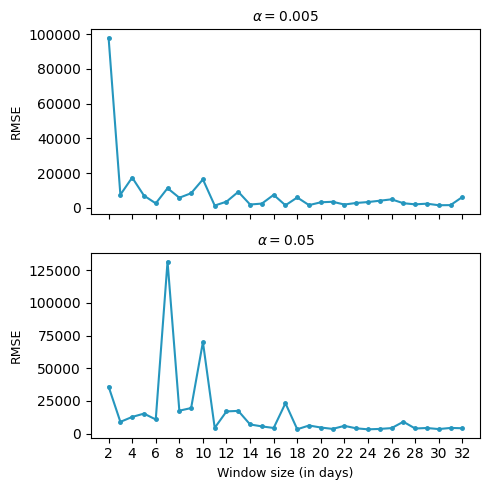

In [8]:
n_trunc = len(trunc_orders)
cmap = mpl.colormaps["viridis"].resampled(n_trunc)  
colors = [cmap(i) for i in range(n_trunc)]
colors.insert(0,"#2596be")

setup_latex_plotting()

x = np.arange(n_windows)
tick_step = 2
xticks = np.arange(delay_days, n_windows + delay_days, tick_step)
xticklabels = xticks

fig, axes = plt.subplots(nrows=2, ncols=1, figsize=(5, 5), sharex=True)

for i, alpha in enumerate(smooth_params[:2]):  
    ax = axes[i]
    for j, d in enumerate(trunc_orders):
        ax.plot(
            x + delay_days,
            error_alpha_w[i, j],
            marker='.',
            markersize=5,
            color=colors[j],
            #label=f"Truncation order = {d}"
        )
    ax.set_ylabel(metric.upper(),fontsize=9)
    # ax.legend(fontsize=9)
    ax.set_title(rf"$\alpha = {alpha}$",fontsize=10)

axes[-1].set_xticks(xticks)
axes[-1].set_xticklabels(xticklabels)
axes[-1].set_xlabel("Window size (in days)",fontsize=9)

plt.tight_layout()
plt.show()
